In [1]:
from pathlib import Path
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
import tensorflow as tf

warnings.filterwarnings("ignore")

# Set the locations of the three input files directly.
TRAIN_FILE = Path(r"C:\Users\hp\Desktop\Lessons\archive\PM_train.csv")
TEST_FILE = Path(r"C:\Users\hp\Desktop\Lessons\archive\PM_test.csv")
TRUTH_FILE = Path(r"C:\Users\hp\Desktop\Lessons\archive\PM_truth.csv")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Using training file:", TRAIN_FILE)
print("Using test file:", TEST_FILE)
print("Using truth file:", TRUTH_FILE)
print("TensorFlow version:", tf.__version__)

Using training file: C:\Users\hp\Desktop\Lessons\archive\PM_train.csv
Using test file: C:\Users\hp\Desktop\Lessons\archive\PM_test.csv
Using truth file: C:\Users\hp\Desktop\Lessons\archive\PM_truth.csv
TensorFlow version: 2.22.0-rc0


In [2]:
train = pd.read_csv(TRAIN_FILE)
test = pd.read_csv(TEST_FILE)
truth = pd.read_csv(TRUTH_FILE)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Truth shape:", truth.shape)
display(train.head())
display(truth.head())
print("Missing train values:", int(train.isna().sum().sum()))
print("Missing test values:", int(test.isna().sum().sum()))

Train shape: (20631, 26)
Test shape: (13096, 26)
Truth shape: (100, 2)


,id,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,id,cycle
0,1,112
1,2,98
2,3,69
3,4,82
4,5,91


Missing train values: 0
Missing test values: 0


In [ ]:
#Data Preprocessing module

# Sort rows so every engine has its cycles in time order.
train = train.sort_values(["id", "cycle"]).reset_index(drop=True)
test = test.sort_values(["id", "cycle"]).reset_index(drop=True)
truth = truth.sort_values("id").reset_index(drop=True)

# Build the target for every training row.
train_failure_cycle = train.groupby("id")["cycle"].max().rename("failure_cycle")
train = train.merge(train_failure_cycle, on="id")
train["RUL"] = (train["failure_cycle"] - train["cycle"]).clip(upper=125)

# Build the final observed row and its true RUL for each test engine.
test_last = test.groupby("id", as_index=False).tail(1).copy()
test_last = test_last.merge(truth.rename(columns={"cycle": "future_cycles"}), on="id")
test_last["RUL"] = test_last["future_cycles"]

print("Training RUL range:", train["RUL"].min(), "to", train["RUL"].max())
print("Test engines with truth values:", test_last["id"].nunique())
display(train[["id", "cycle", "failure_cycle", "RUL"]].head())
display(test_last[["id", "cycle", "future_cycles", "RUL"]].head())

Training RUL range: 0 to 125
Test engines with truth values: 100


,id,cycle,failure_cycle,RUL
0,1,1,192,125
1,1,2,192,125
2,1,3,192,125
3,1,4,192,125
4,1,5,192,125


,id,cycle,future_cycles,RUL
0,1,31,112,112
1,2,49,98,98
2,3,126,69,69
3,4,106,82,82
4,5,98,91,91


In [ ]:
#Feature selection/extraction module

ID_COLUMN = "id"
TARGET_COLUMN = "RUL"
WINDOW_SIZE = 30
CORRELATION_THRESHOLD = 0.05

# Do not give the models the identifier or the helper column.
candidate_features = [
    column for column in train.columns
    if column not in [ID_COLUMN, TARGET_COLUMN, "failure_cycle"]
]

# Remove columns that do not change in the training data.
variable_features = [
    column for column in candidate_features
    if train[column].nunique() > 1
]

# Keep features with a small but measurable relationship to RUL.
correlations = train[variable_features + [TARGET_COLUMN]].corr()[TARGET_COLUMN]
selected_features = [
    column for column in variable_features
    if abs(correlations[column]) >= CORRELATION_THRESHOLD
]

# Keep the pipeline safe if a different dataset has weaker correlations.
if not selected_features:
    selected_features = variable_features

print("Removed constant columns:", sorted(set(candidate_features) - set(variable_features)))
print("Selected features:", selected_features)
print("Number of selected features:", len(selected_features))

Removed constant columns: ['s1', 's10', 's16', 's18', 's19', 's5', 'setting3']
Selected features: ['cycle', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
Number of selected features: 16


In [5]:
# Scale using training data only, which prevents test-data leakage.
scaler = StandardScaler()
scaler.fit(train[selected_features])

train_scaled = train.copy()
test_scaled = test.copy()
train_scaled[selected_features] = scaler.transform(train[selected_features])
test_scaled[selected_features] = scaler.transform(test[selected_features])

print("Scaled training data shape:", train_scaled[selected_features].shape)
print("Scaled test data shape:", test_scaled[selected_features].shape)

Scaled training data shape: (20631, 16)
Scaled test data shape: (13096, 16)


In [6]:
def make_lstm_sequences(data, features, window_size, target_column=None):
    # Create one sequence for every possible window in each engine.
    sequences = []
    labels = []
    engine_ids = []

    for engine_id, engine_data in data.groupby("id"):
        engine_data = engine_data.sort_values("cycle")
        values = engine_data[features].to_numpy(dtype=np.float32)
        if len(values) < window_size:
            continue

        for end in range(window_size, len(values) + 1):
            sequences.append(values[end - window_size:end])
            engine_ids.append(engine_id)
            if target_column is not None:
                labels.append(engine_data[target_column].iloc[end - 1])

    X = np.asarray(sequences, dtype=np.float32)
    ids = np.asarray(engine_ids)
    if target_column is None:
        return X, ids
    return X, np.asarray(labels, dtype=np.float32), ids


def make_last_lstm_sequences(data, features, window_size):
    # Create only the final sequence for each test engine.
    sequences = []
    engine_ids = []

    for engine_id, engine_data in data.groupby("id"):
        engine_data = engine_data.sort_values("cycle")
        values = engine_data[features].to_numpy(dtype=np.float32)

        # Pad very short histories at the beginning if needed.
        if len(values) < window_size:
            padding = np.repeat(values[[0]], window_size - len(values), axis=0)
            values = np.vstack([padding, values])

        sequences.append(values[-window_size:])
        engine_ids.append(engine_id)

    return np.asarray(sequences, dtype=np.float32), np.asarray(engine_ids)


X_lstm, y_lstm, lstm_engine_ids = make_lstm_sequences(
    train_scaled, selected_features, WINDOW_SIZE, TARGET_COLUMN
)
X_test_lstm, test_lstm_ids = make_last_lstm_sequences(
    test_scaled, selected_features, WINDOW_SIZE
)

# Split by engine to avoid mixing windows from the same engine across splits.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_indices, validation_indices = next(
    splitter.split(X_lstm, y_lstm, groups=lstm_engine_ids)
)

X_lstm_train = X_lstm[train_indices]
y_lstm_train = y_lstm[train_indices]
X_lstm_validation = X_lstm[validation_indices]
y_lstm_validation = y_lstm[validation_indices]

print("LSTM training sequences:", X_lstm_train.shape)
print("LSTM validation sequences:", X_lstm_validation.shape)

LSTM training sequences: (14241, 30, 16)
LSTM validation sequences: (3490, 30, 16)


In [7]:
# Simple LSTM configuration for RUL regression.
tf.keras.backend.clear_session()
lstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW_SIZE, len(selected_features))),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1)
])

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_lstm_train,
    y_lstm_train,
    validation_data=(X_lstm_validation, y_lstm_validation),
    epochs=15,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15



  1/112 ━━━━━━━━━━━━━━━━━━━━ 2:28 1s/step - loss: 7637.3398 - mae: 76.8164


  6/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 8354.2783 - mae: 81.6106


 12/112 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 8354.0039 - mae: 81.3266


 19/112 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 8257.8232 - mae: 80.8958 


 26/112 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 8150.1841 - mae: 80.2734

... (261 outputs left out)


 95/112 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 104.0254 - mae: 7.1910


101/112 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 103.2984 - mae: 7.1590


107/112 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 102.8046 - mae: 7.1424


112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 102.1382 - mae: 7.1223 - val_loss: 153.6885 - val_mae: 8.3307


In [8]:
# LSTM results are kept in their own table.
lstm_predictions = lstm_model.predict(X_test_lstm, verbose=0).reshape(-1)
actual_lstm = test_last.set_index("id").loc[test_lstm_ids, "RUL"].to_numpy()

lstm_results = pd.DataFrame({
    "id": test_lstm_ids,
    "actual_RUL": actual_lstm,
    "predicted_RUL": lstm_predictions
})
lstm_results["absolute_error"] = abs(
    lstm_results["actual_RUL"] - lstm_results["predicted_RUL"]
)

lstm_mae = mean_absolute_error(actual_lstm, lstm_predictions)
lstm_rmse = np.sqrt(mean_squared_error(actual_lstm, lstm_predictions))

print("LSTM evaluation only")
print(f"LSTM MAE: {lstm_mae:.2f} cycles")
print(f"LSTM RMSE: {lstm_rmse:.2f} cycles")
display(lstm_results.head(10))

LSTM evaluation only
LSTM MAE: 10.52 cycles
LSTM RMSE: 14.48 cycles


,id,actual_RUL,predicted_RUL,absolute_error
0,1,112,121.688606,9.688606
1,2,98,121.003670,23.003670
2,3,69,59.166454,9.833546
3,4,82,87.566208,5.566208
4,5,91,108.964005,17.964005
5,6,93,101.255814,8.255814
6,7,91,104.053101,13.053101
7,8,95,104.158379,9.158379
8,9,111,121.458420,10.458420
9,10,96,93.553215,2.446785


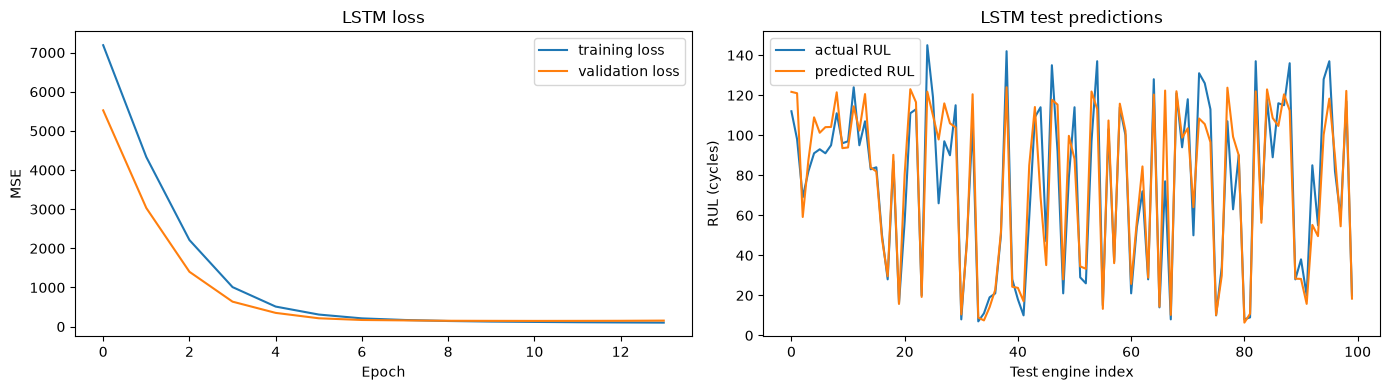

In [9]:
# Plot the LSTM learning curves and final predictions separately.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(lstm_history.history["loss"], label="training loss")
axes[0].plot(lstm_history.history["val_loss"], label="validation loss")
axes[0].set_title("LSTM loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()

axes[1].plot(actual_lstm, label="actual RUL")
axes[1].plot(lstm_predictions, label="predicted RUL")
axes[1].set_title("LSTM test predictions")
axes[1].set_xlabel("Test engine index")
axes[1].set_ylabel("RUL (cycles)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [10]:
# Use an engine-level split for XGBoost validation as well.
xgb_splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
xgb_train_indices, xgb_validation_indices = next(
    xgb_splitter.split(train_scaled, train_scaled[TARGET_COLUMN], groups=train_scaled[ID_COLUMN])
)

X_xgb_train = train_scaled.iloc[xgb_train_indices][selected_features]
y_xgb_train = train_scaled.iloc[xgb_train_indices][TARGET_COLUMN]
X_xgb_validation = train_scaled.iloc[xgb_validation_indices][selected_features]
y_xgb_validation = train_scaled.iloc[xgb_validation_indices][TARGET_COLUMN]

# Simple gradient-boosted tree configuration.
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=SEED,
    n_jobs=2
)

xgb_model.fit(
    X_xgb_train,
    y_xgb_train,
    eval_set=[(X_xgb_validation, y_xgb_validation)],
    verbose=False
)
print("XGBoost model trained with", len(selected_features), "features")

XGBoost model trained with 16 features


In [11]:
# XGBoost results are kept in a different table from the LSTM results.
test_scaled_last = test_scaled.groupby("id", as_index=False).tail(1)
X_xgb_test = test_scaled_last.set_index("id").loc[test_last["id"], selected_features]
xgb_predictions = xgb_model.predict(X_xgb_test)
actual_xgb = test_last.set_index("id").loc[test_last["id"], "RUL"].to_numpy()

xgb_results = pd.DataFrame({
    "id": test_last["id"].to_numpy(),
    "actual_RUL": actual_xgb,
    "predicted_RUL": xgb_predictions
})
xgb_results["absolute_error"] = abs(
    xgb_results["actual_RUL"] - xgb_results["predicted_RUL"]
)

xgb_mae = mean_absolute_error(actual_xgb, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(actual_xgb, xgb_predictions))

print("XGBoost evaluation only")
print(f"XGBoost MAE: {xgb_mae:.2f} cycles")
print(f"XGBoost RMSE: {xgb_rmse:.2f} cycles")
display(xgb_results.head(10))

XGBoost evaluation only
XGBoost MAE: 13.40 cycles
XGBoost RMSE: 18.12 cycles


,id,actual_RUL,predicted_RUL,absolute_error
0,1,112,124.174362,12.174362
1,2,98,120.848244,22.848244
2,3,69,55.126118,13.873882
3,4,82,81.265472,0.734528
4,5,91,98.240242,7.240242
5,6,93,88.759827,4.240173
6,7,91,103.798668,12.798668
7,8,95,67.577118,27.422882
8,9,111,118.893509,7.893509
9,10,96,102.457260,6.457260


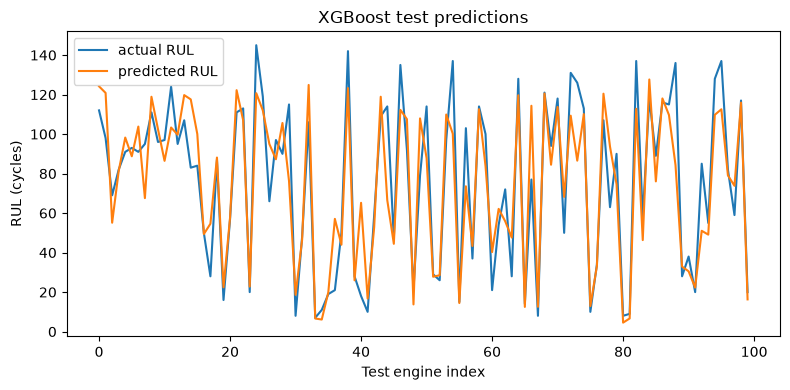

In [12]:
# Plot XGBoost predictions only.
plt.figure(figsize=(8, 4))
plt.plot(actual_xgb, label="actual RUL")
plt.plot(xgb_predictions, label="predicted RUL")
plt.title("XGBoost test predictions")
plt.xlabel("Test engine index")
plt.ylabel("RUL (cycles)")
plt.legend()
plt.tight_layout()
plt.show()